# Train T

This tutorial uses the paired 5-dimensional RNA and ATAC PCA representations produced from the [scMultiSim R workflow](generate_data.R) and used by `TraInf/Synthetic/data/MLPVisual.ipynb`. The [prepared data files](https://github.com/shankswang953/COATI/tree/main/examples/data/scmultisim) download automatically when they are not present in a local COATI checkout.

No pretrained map is loaded. We first assemble paired AnnData, evaluate the map by five-fold testing, and then fit the final $T:\mathrm{RNA}\rightarrow\mathrm{ATAC}$ on all supplied cells.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import json
import uuid

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import torch
from threadpoolctl import threadpool_limits

import coati as ct
from coati.maps import load_map, train_map

%matplotlib inline
threadpool_limits(limits=1)
torch.set_num_threads(1)
plt.rcParams.update({"font.family": "Arial", "font.size": 11})

TIME_KEYS = ("time1", "time2", "time3", "time4")
TIME_VALUES = np.arange(4, dtype=float)
RAW_DATA_BASE_URL = "https://raw.githubusercontent.com/shankswang953/COATI/main/examples/data/scmultisim"
SOURCE_FILES = (
    "all_time_scRNA_pca.npz",
    "all_time_scATAC_pca.npz",
    "all_time_celltype.npz",
)
run_dir = Path("outputs") / ("scmultisim-map-" + uuid.uuid4().hex[:8])
device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
print("Map training device:", device)

Map training device: mps


## Prepare paired AnnData

Rows are paired within each time point. RNA is stored in `obsm["X_pca"]`, ATAC in `obsm["X_atac"]`, and the R-generated population labels are stored in canonical `obs["celltype"]` together with `time` and `barcode`.

The generated AnnData is written to a fixed `scmultisim.h5ad` path. Re-running this cell intentionally replaces that file.

In [2]:
local_data_dir = next((
    parent / "examples" / "data" / "scmultisim"
    for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "examples" / "data" / "scmultisim").is_dir()
), None)
data_dir = local_data_dir or Path("outputs") / "scmultisim-data"
data_dir.mkdir(parents=True, exist_ok=True)


def obtain_data(filename):
    path = data_dir / filename
    if not path.is_file():
        print("Downloading", filename)
        urlretrieve(f"{RAW_DATA_BASE_URL}/{filename}", path)
    return path


with np.load(obtain_data(SOURCE_FILES[0]), allow_pickle=False) as archive:
    rna = [np.asarray(archive[key], dtype=np.float32) for key in TIME_KEYS]
with np.load(obtain_data(SOURCE_FILES[1]), allow_pickle=False) as archive:
    atac = [np.asarray(archive[key], dtype=np.float32) for key in TIME_KEYS]
with np.load(obtain_data(SOURCE_FILES[2]), allow_pickle=False) as archive:
    celltypes_by_time = [np.asarray(archive[key], dtype=str) for key in TIME_KEYS]

for key, x, y, labels in zip(TIME_KEYS, rna, atac, celltypes_by_time):
    if x.shape[0] != y.shape[0] or len(labels) != len(x) or x.shape[1:] != y.shape[1:] or x.shape[1] != 5:
        raise ValueError(f"Unexpected paired shapes at {key}: RNA {x.shape}, ATAC {y.shape}, labels {labels.shape}")

barcodes = np.concatenate([
    [f"scmultisim-{key}-{index:05d}" for index in range(len(x))]
    for key, x in zip(TIME_KEYS, rna)
])
stages = np.concatenate([np.repeat(key, len(x)) for key, x in zip(TIME_KEYS, rna)])
celltypes = np.concatenate(celltypes_by_time)

cells = ct.prepare_anndata(
    rna, time=TIME_VALUES, celltype=celltypes,
    barcode=barcodes, use_rep="X_pca",
    secondary=atac, secondary_key="X_atac", warn=False,
)
cells.obs["stage"] = pd.Categorical(stages, categories=TIME_KEYS, ordered=True)

assert cells.obs_names.is_unique
assert cells.obsm["X_pca"].shape == cells.obsm["X_atac"].shape == (10000, 5)
anndata_path = data_dir / "scmultisim.h5ad"
cells.write_h5ad(anndata_path, compression="gzip")
print(cells)
print("Wrote:", anndata_path.resolve())

counts_table = pd.DataFrame({
    "stage": TIME_KEYS,
    "cells": [len(part) for part in rna],
})
display(
    counts_table.style.hide(axis="index")
    .set_properties(**{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
)

AnnData object with n_obs × n_vars = 10000 × 5
    obs: 'time', 'celltype', 'barcode', 'stage'
    uns: 'coati_input'
    obsm: 'X_pca', 'X_atac'
Wrote: /Users/jingfeng/local/project/COATI/examples/data/scmultisim/scmultisim.h5ad


stage,cells
time1,2006
time2,2001
time3,3008
time4,2985


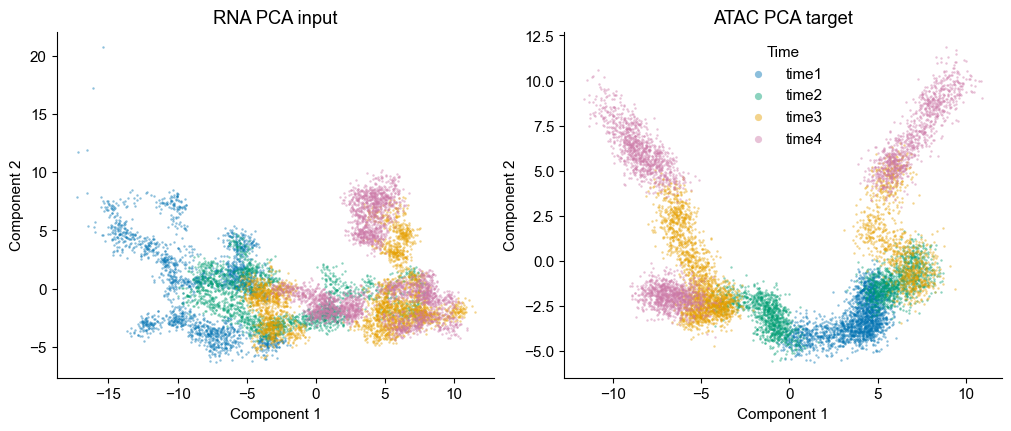

In [3]:
stage_palette = dict(zip(TIME_KEYS, ["#0072B2", "#009E73", "#E69F00", "#CC79A7"]))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
for ax, values, title in zip(
    axes, (cells.obsm["X_pca"], cells.obsm["X_atac"]),
    ("RNA PCA input", "ATAC PCA target"),
):
    for stage in TIME_KEYS:
        mask = cells.obs["stage"].to_numpy() == stage
        ax.scatter(*values[mask, :2].T, s=3, alpha=.45, linewidths=0,
                   color=stage_palette[stage], label=stage, rasterized=True)
    ax.set(title=title, xlabel="Component 1", ylabel="Component 2")
    ax.spines[["top", "right"]].set_visible(False)
axes[1].legend(frameon=False, title="Time", markerscale=3)
plt.show()

## 5-fold test

Cells are assigned to five folds separately within every time point, so each test fold contains all four stages. For each fold, COATI trains on the other four folds, uses an internal validation split for checkpoint selection, and evaluates only the held-out fold.

The original experiment used four hidden layers of width 512. `hidden_dim=512, n_layers=5` keeps the same input–four-hidden–output depth while COATI adds feature standardization, early stopping, checkpoint reload support, and per-stage diagnostics.

In [4]:
times = cells.obs["time"].to_numpy()
fold_id = np.empty(cells.n_obs, dtype=int)
rng = np.random.default_rng(17)
for time in TIME_VALUES:
    rows = rng.permutation(np.flatnonzero(times == time))
    fold_id[rows] = np.arange(len(rows)) % 5
cells.obs["test_fold"] = fold_id + 1

fold_counts = pd.crosstab(cells.obs["test_fold"], cells.obs["stage"])
assert fold_counts.shape == (5, 4)
fold_counts

stage,time1,time2,time3,time4
test_fold,,,,
1,402,401,602,597
2,401,400,602,597
3,401,400,602,597
4,401,400,601,597
5,401,400,601,597


In [5]:
map_config = ct.MapConfig(
    hidden_dim=512, n_layers=5,
    epochs=400, batch_size=1024, lr=2e-3, weight_decay=0.0,
    validation_fraction=.20, patience=50,
    eval_samples=256, eval_repeats=5,
)


def map_points(model, points, batch_size=1024):
    model.eval()
    with torch.no_grad():
        return np.concatenate([
            model(torch.as_tensor(points[start:start + batch_size],
                                  dtype=torch.float32, device=device)).cpu().numpy()
            for start in range(0, len(points), batch_size)
        ])


x, y = cells.obsm["X_pca"], cells.obsm["X_atac"]
fold_results = []
for fold in range(5):
    train_rows = np.flatnonzero(fold_id != fold)
    test_rows = np.flatnonzero(fold_id == fold)
    training = ct.TemporalData.from_anndata(
        cells[train_rows].copy(), obsm_key="X_pca", secondary_obsm_key="X_atac"
    )
    fold_map, fold_report = train_map(
        training, kind="mlp", config=map_config,
        directory=run_dir / f"fold_{fold + 1}" / "map",
        device=device, seed=fold, verbose=False,
    )
    prediction = map_points(fold_map, x[test_rows])
    mse = float(np.mean((prediction - y[test_rows]) ** 2))
    baseline_error = 0.0
    for time in TIME_VALUES:
        test_mask = times[test_rows] == time
        reference_mean = y[train_rows][times[train_rows] == time].mean(0)
        baseline_error += float(np.sum((reference_mean - y[test_rows][test_mask]) ** 2))
    fold_results.append({
        "fold": fold + 1,
        "test_cells": len(test_rows),
        "best_epoch": fold_report["best_epoch"],
        "paired_rmse": np.sqrt(mse),
        "normalized_mse": mse / (baseline_error / y[test_rows].size),
    })
    print(f"Fold {fold + 1}/5 complete")

fold_quality = pd.DataFrame(fold_results)
display(fold_quality.style.hide(axis="index").format({
    "paired_rmse": "{:.4f}", "normalized_mse": "{:.4f}"
}).set_properties(**{"text-align": "left"}).set_table_styles([
    {"selector": "th", "props": [("text-align", "left")]}
]))

Fold 1/5 complete


Fold 2/5 complete


Fold 3/5 complete


Fold 4/5 complete


Fold 5/5 complete


fold,test_cells,best_epoch,paired_rmse,normalized_mse
1,2002,119,0.7337,0.0490
2,2000,126,0.7355,0.0490
3,2000,129,0.7323,0.0486
4,1999,129,0.7324,0.0498
5,1999,135,0.7295,0.0491


[COATI map] Epoch 1/400, standardized validation MSE 0.290887.


[COATI map] Epoch 25/400, standardized validation MSE 0.0676671.


[COATI map] Epoch 50/400, standardized validation MSE 0.0616453.


[COATI map] Epoch 75/400, standardized validation MSE 0.0583627.


[COATI map] Epoch 100/400, standardized validation MSE 0.0587171.


[COATI map] Epoch 125/400, standardized validation MSE 0.059399.


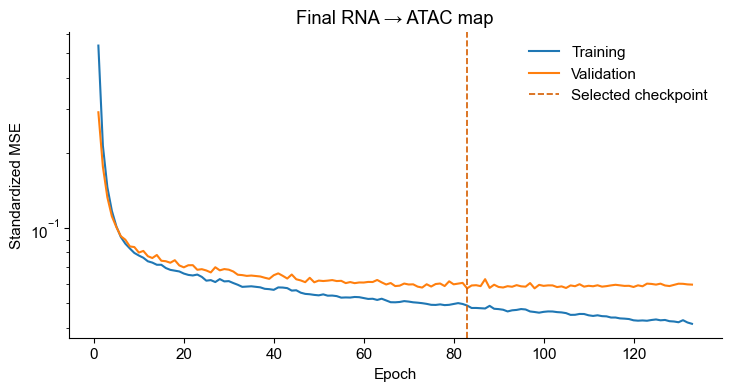

Best epoch: 83 | completed: 133 | validation: passed


In [6]:
all_paired = ct.TemporalData.from_anndata(
    cells, obsm_key="X_pca", secondary_obsm_key="X_atac"
)
T, map_report = train_map(
    all_paired, kind="mlp", config=map_config,
    directory=run_dir / "final_map", device=device, seed=0, verbose=True,
)
history = pd.read_json(run_dir / "final_map" / "history.json")

fig, ax = plt.subplots(figsize=(7.2, 3.8), layout="constrained")
ax.plot(history["epoch"], history["train_standardized_mse"], label="Training")
ax.plot(history["epoch"], history["validation_standardized_mse"], label="Validation")
ax.axvline(map_report["best_epoch"], color="#D55E00", linestyle="--",
           linewidth=1.2, label="Selected checkpoint")
ax.set(xlabel="Epoch", ylabel="Standardized MSE",
       title="Final RNA → ATAC map", yscale="log")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()
print("Best epoch:", map_report["best_epoch"],
      "| completed:", map_report["epochs_completed"],
      "| validation:", map_report["status"])

## Map all RNA cells to ATAC

The final fitted map is applied to every RNA cell. Observed and mapped cells are shown directly in the same ATAC PCA coordinates, without an additional embedding fit.

In [7]:
mapped_atac = map_points(T, x)
restored = load_map(run_dir / "final_map" / "model.pt", device=device)
np.testing.assert_array_equal(mapped_atac, map_points(restored, x))
assert mapped_atac.shape == y.shape and np.isfinite(mapped_atac).all()
print("Mapped RNA cells:", mapped_atac.shape)
print("Exact checkpoint reload: passed")

Mapped RNA cells: (10000, 5)
Exact checkpoint reload: passed


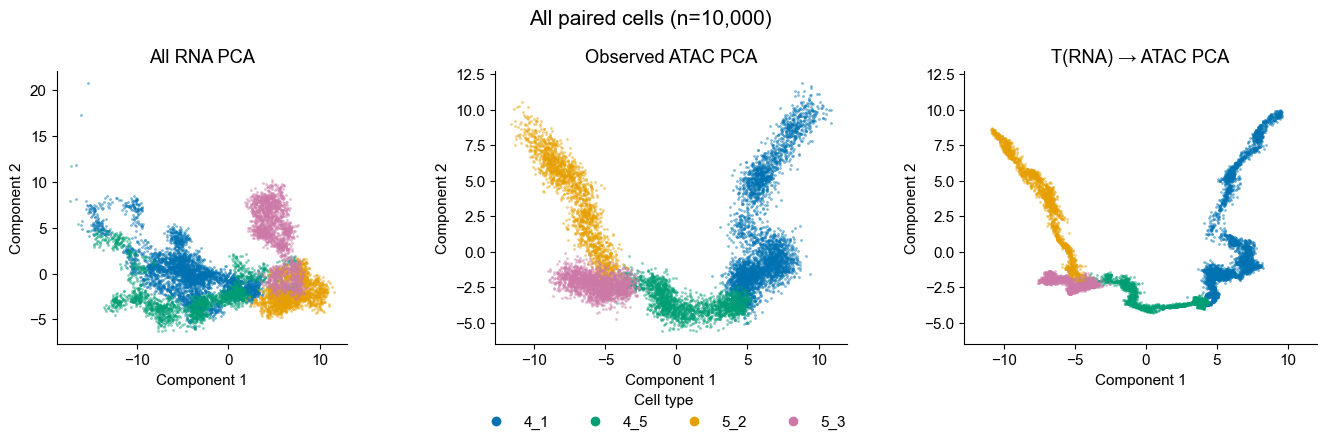

In [8]:
coordinates = [x[:, :2], y[:, :2], mapped_atac[:, :2]]
titles = ["All RNA PCA", "Observed ATAC PCA", "T(RNA) → ATAC PCA"]
celltype_names = sorted(np.unique(celltypes))
celltype_palette = dict(zip(celltype_names, ["#0072B2", "#009E73", "#E69F00", "#CC79A7"]))
atac_limits = np.vstack(coordinates[1:])
low, high = atac_limits.min(0), atac_limits.max(0)
pad = .05 * np.maximum(high-low, 1.)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for panel, (ax, points, title) in enumerate(zip(axes, coordinates, titles)):
    for celltype in celltype_names:
        mask = celltypes == celltype
        ax.scatter(*points[mask].T, s=4, alpha=.5, linewidths=0,
                   color=celltype_palette[celltype], rasterized=True)
    ax.set(title=title, xlabel="Component 1", ylabel="Component 2")
    ax.set_aspect("equal", adjustable="box")
    ax.spines[["top", "right"]].set_visible(False)
    if panel:
        ax.set(xlim=(low[0]-pad[0], high[0]+pad[0]),
               ylim=(low[1]-pad[1], high[1]+pad[1]))
handles = [Line2D([], [], marker="o", linestyle="", color=celltype_palette[name],
                  label=name, markersize=6) for name in celltype_names]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, title="Cell type")
fig.suptitle(f"All paired cells (n={cells.n_obs:,})", fontsize=15, y=.98)
fig.subplots_adjust(left=.04, right=.99, bottom=.22, top=.84, wspace=.20)
plt.show()

In [9]:
summary = {
    "dataset": "scMultiSim",
    "source": "R-generated paired RNA and ATAC; prepared 5D PCA views from MLPVisual.ipynb",
    "cells": int(cells.n_obs),
    "anndata": str(anndata_path),
    "map_kind": "mlp",
    "map_config": map_config.to_dict(),
    "five_fold_test": fold_quality.to_dict(orient="records"),
    "final_map_report": map_report,
    "mapped_all_cells": True,
    "exact_checkpoint_reload": True,
}
(run_dir / "map_report.json").write_text(json.dumps(summary, indent=2) + "\n")
print("AnnData:", anndata_path.resolve())
print("Final map and reports:", run_dir.resolve())

AnnData: /Users/jingfeng/local/project/COATI/examples/data/scmultisim/scmultisim.h5ad
Final map and reports: /Users/jingfeng/local/project/COATI/notebooks/scMultisim/outputs/scmultisim-map-8e95e576
